# Step 4b Run the FP32 digit-recognition baseline

This increment adds a program that **guesses the digit in an MNIST image**.
It trains a small FP32 network, shows correct and incorrect guesses, and measures
accuracy on all 10,000 test images. The later INT8 version will be compared with
this baseline.

In Colab, choose **Runtime → Run all**. The notebook downloads about **12 MB** of
public MNIST data the first time and trains on the CPU. Training adds runtime;
it is not an accelerator performance measurement. NumPy and Matplotlib are enough.
No repository files, saved-model download, GPU, or package installation is needed.

The fixed recipe is seed 530 and eight training epochs. Results can vary slightly
across numerical libraries. The final cell should finish with
**All 11 data and FP32 baseline checks passed.**


## 1 Images and known answers

MNIST contains small grayscale pictures of handwritten digits. Each picture is
**28 × 28 pixels**. Its **label** is the known digit, from 0 through 9.

The label is the answer we will later compare with the network's prediction.
The first gallery displays known labels. Network predictions appear later in this notebook.

The downloaded files contain pixel values and labels in a compact binary format
called IDX. The loader below checks file identity before decoding their headers
and contents. The checksum is a fingerprint of the published file.


In [45]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import gzip
import hashlib
from pathlib import Path
import struct
import sys
import unittest
import urllib.request

import numpy as np
%pip install matplotlib
import matplotlib.pyplot as plt

CACHE = Path("mnist-cache")
MIRROR = "https://ossci-datasets.s3.amazonaws.com/mnist/"
MNIST_FILES = {
    "train-images-idx3-ubyte.gz": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
    "train-labels-idx1-ubyte.gz": "d53e105ee54ea40749a09fcbcd1e9432",
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}


def check_file_identity(payload, expected_md5):
    if hashlib.md5(payload).hexdigest() != expected_md5:
        raise ValueError("MNIST file checksum does not match the published file.")
    return payload


def fetch_mnist_file(filename):
    CACHE.mkdir(exist_ok=True)
    path = CACHE / filename
    if path.exists():
        payload = check_file_identity(path.read_bytes(), MNIST_FILES[filename])
    else:
        print("Downloading", filename)
        with urllib.request.urlopen(MIRROR + filename, timeout=30) as response:
            payload = check_file_identity(response.read(), MNIST_FILES[filename])
        path.write_bytes(payload)
    return payload


def normalize_pixels(pixels):
    return pixels.astype(np.float32) / np.float32(255)



def decode_images(payload):
    if len(payload) < 16:
        raise ValueError("Truncated image header.")
    magic, count, height, width = struct.unpack(">IIII", payload[:16])
    if magic != 2051 or (height, width) != (28, 28) or count < 1:
        raise ValueError("Invalid MNIST image header.")
    if len(payload) != 16 + count * height * width:
        raise ValueError("Image payload length does not match its header.")
    return np.frombuffer(payload, dtype=np.uint8, offset=16).reshape(count, 784)


def decode_labels(payload):
    if len(payload) < 8:
        raise ValueError("Truncated label header.")
    magic, count = struct.unpack(">II", payload[:8])
    if magic != 2049 or count < 1 or len(payload) != 8 + count:
        raise ValueError("Invalid MNIST label file.")
    labels = np.frombuffer(payload, dtype=np.uint8, offset=8)
    if np.any(labels > 9):
        raise ValueError("MNIST labels must be digits 0 through 9.")
    return labels

print("Verified MNIST loader ready.")


Note: you may need to restart the kernel to use updated packages.
Verified MNIST loader ready.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2 Load the test set

Each original pixel is an integer from **0 to 255**: black through white. Dividing
by 255 represents that pixel on a **0 to 1** scale for the future network input.

A 28 × 28 picture contains `28 × 28 = 784` pixels. The loader stores each picture
as one row of 784 values. The same values can be reshaped into a picture again.

These files are the held-out test set. Training and calibration use
separate data below, so test labels remain a fair accuracy check.


In [46]:
image_file = fetch_mnist_file("t10k-images-idx3-ubyte.gz")
label_file = fetch_mnist_file("t10k-labels-idx1-ubyte.gz")
pixels = decode_images(gzip.decompress(image_file))
labels = decode_labels(gzip.decompress(label_file))
if pixels.shape != (10000, 784) or labels.shape != (10000,):
    raise ValueError("Expected 10,000 images with 784 pixels and one label each.")
inputs = normalize_pixels(pixels)
print("Images:", len(inputs))
print("Input table shape:", inputs.shape)
print("Labels:", len(labels))
print("Original pixel type:", pixels.dtype)
print("Normalized input type:", inputs.dtype)
print("Original pixel range:", int(pixels.min()), "to", int(pixels.max()))
print("Normalized range:", float(inputs.min()), "to", float(inputs.max()))


Images: 10000
Input table shape: (10000, 784)
Labels: 10000
Original pixel type: uint8
Normalized input type: float32
Original pixel range: 0 to 255
Normalized range: 0.0 to 1.0


## 3 Look at the images

These are the first twelve test images. Each title shows the label supplied with
the dataset. It is a known answer, not a guess made by our program.


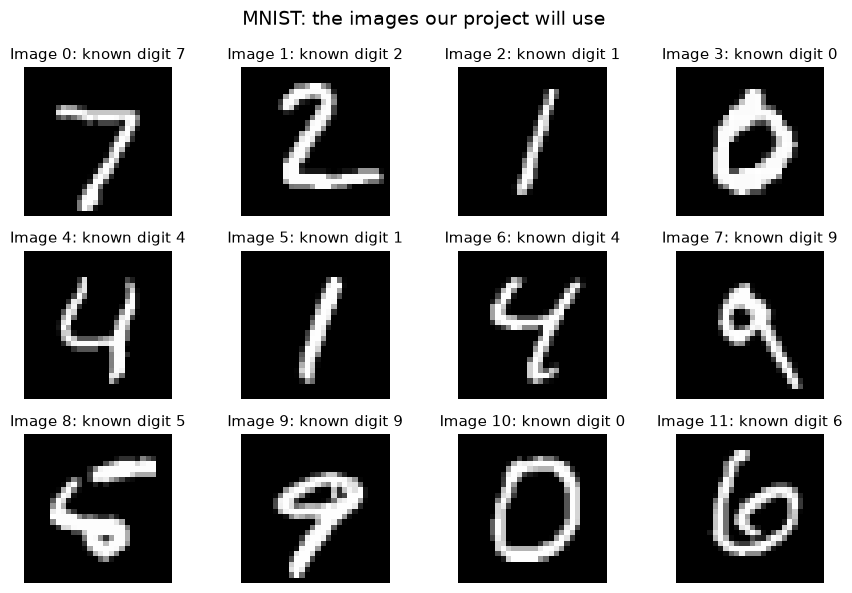

In [47]:
fig, axes = plt.subplots(3, 4, figsize=(9, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(inputs[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Image {index}: known digit {labels[index]}", fontsize=11)
    ax.axis("off")
fig.suptitle("MNIST: the images our project will use", fontsize=14)
fig.tight_layout()
plt.show()


## 4 Connect one picture to its numbers

Change `image_index` to another value from 0 through 9999 and rerun the next cell
to inspect a different image. A network will receive these pixel numbers and
calculate ten scores, one for each digit. That calculation follows below.


In [48]:
image_index = 0
if not 0 <= image_index < len(inputs):
    raise ValueError("image_index must be between 0 and 9999.")
picture = inputs[image_index].reshape(28, 28)
print("Image index:", image_index)
print("Known digit:", int(labels[image_index]))
print("Picture shape:", picture.shape)
print("Network input shape:", inputs[image_index:image_index + 1].shape)
print("Pixels above zero:", int(np.count_nonzero(picture)))
print("Middle row, rounded for display:")
print(np.round(picture[14], 2))


Image index: 0
Known digit: 7
Picture shape: (28, 28)
Network input shape: (1, 784)
Pixels above zero: 116
Middle row, rounded for display:
[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.23 0.98 1.   0.24 0.   0.   0.   0.   0.   0.   0.   0.  ]


## 5 Load separate training data

**Training** learns the network's weights from examples. **Inference** uses the
learned weights to guess a digit. Our accelerator project will study inference.

The original 60,000 training images are split with a fixed seed:

| Group | Images | Purpose |
|---|---:|---|
| Training | 54,000 | Learn weights |
| Validation | 5,000 | Monitor learning |
| Calibration reserve | 1,000 | Set aside for the later INT8 increment |

The 10,000 test images above stay outside training. A seed makes the random split
and initial weights repeatable within the same numerical setup.


In [49]:
def split_indices(seed=530):
    order = np.random.default_rng(seed).permutation(60000).astype(np.int32)
    return {"training": order[:54000], "validation": order[54000:59000],
            "calibration": order[59000:]}

train_image_file = fetch_mnist_file("train-images-idx3-ubyte.gz")
train_label_file = fetch_mnist_file("train-labels-idx1-ubyte.gz")
train_pixels = decode_images(gzip.decompress(train_image_file))
train_labels = decode_labels(gzip.decompress(train_label_file))
if train_pixels.shape != (60000, 784) or train_labels.shape != (60000,):
    raise ValueError("Expected 60,000 training images and labels.")
train_inputs = normalize_pixels(train_pixels)
indices = split_indices(seed=530)
for name, selected in indices.items():
    print(f"{name}: {len(selected):,} images")
print("Test images kept separate:", len(labels))


training: 54,000 images
validation: 5,000 images
calibration: 1,000 images
Test images kept separate: 10000


## 6 Define a small network

The network performs two matrix multiplications:

```text
784 pixel values → 64 intermediate values → 10 digit scores
```

Each layer multiplies inputs by learned **weights**, then adds learned offsets
called **biases**. Between layers, **ReLU** replaces negative values with zero.
The digit with the largest final score is the prediction. Scores are not
probabilities.

These matrix calculations will become work for our accelerator model later.
Here they run as FP32 NumPy operations. The training code below learns the weights
automatically; this increment does not model hardware cycles.


In [50]:
def forward_fp32(inputs, model):
    hidden = np.maximum(inputs @ model["w1"] + model["b1"], np.float32(0))
    logits = hidden @ model["w2"] + model["b2"]
    return hidden, logits


def train(inputs, labels, validation_inputs, validation_labels, *, epochs=8,
          hidden_units=64, seed=530, batch_size=128, learning_rate=0.001, progress=print):
    if epochs < 1 or hidden_units < 1 or batch_size < 1:
        raise ValueError("Epochs, hidden units, and batch size must be positive.")
    rng = np.random.default_rng(seed)
    model = {
        "w1": (rng.standard_normal((784, hidden_units)) * np.sqrt(2 / 784)).astype(np.float32),
        "b1": np.zeros(hidden_units, dtype=np.float32),
        "w2": (rng.standard_normal((hidden_units, 10)) * np.sqrt(2 / hidden_units)).astype(np.float32),
        "b2": np.zeros(10, dtype=np.float32),
    }
    first_moment = {key: np.zeros_like(value) for key, value in model.items()}
    second_moment = {key: np.zeros_like(value) for key, value in model.items()}
    step = 0
    history = []
    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(inputs))
        loss_sum, correct = 0.0, 0
        for start in range(0, len(inputs), batch_size):
            indices = order[start:start + batch_size]
            x, y = inputs[indices], labels[indices]
            hidden, logits = forward_fp32(x, model)
            shifted = logits - logits.max(axis=1, keepdims=True)
            exponentials = np.exp(shifted)
            probabilities = exponentials / exponentials.sum(axis=1, keepdims=True)
            loss_sum += float(-np.log(np.maximum(probabilities[np.arange(len(y)), y],
                                                 np.float32(1e-8))).sum())
            correct += int(np.count_nonzero(logits.argmax(axis=1) == y))
            # Derivatives of cross entropy, the two dense layers, and ReLU.
            d_logits = probabilities.copy()
            d_logits[np.arange(len(y)), y] -= np.float32(1)
            d_logits *= np.float32(1 / len(y))
            d_hidden = d_logits @ model["w2"].T
            d_hidden[hidden <= 0] = 0
            gradients = {"w1": x.T @ d_hidden, "b1": d_hidden.sum(axis=0),
                         "w2": hidden.T @ d_logits, "b2": d_logits.sum(axis=0)}
            # Adam optimizer: maintain moving averages for each parameter.
            step += 1
            for key, parameter in model.items():
                first_moment[key] *= np.float32(0.9)
                first_moment[key] += np.float32(0.1) * gradients[key]
                second_moment[key] *= np.float32(0.999)
                second_moment[key] += np.float32(0.001) * gradients[key] ** 2
                corrected_first = first_moment[key] / np.float32(1 - 0.9**step)
                corrected_second = second_moment[key] / np.float32(1 - 0.999**step)
                parameter -= np.float32(learning_rate) * corrected_first / (
                    np.sqrt(corrected_second) + np.float32(1e-8))
        _, validation_logits = forward_fp32(validation_inputs, model)
        item = {"epoch": epoch, "training_loss": loss_sum / len(inputs),
                "training_accuracy": correct / len(inputs),
                "validation_accuracy": float(np.mean(validation_logits.argmax(axis=1) == validation_labels))}
        history.append(item)
        progress(f"Epoch {epoch}/{epochs}: loss={item['training_loss']:.4f}, "
                 f"training={100 * item['training_accuracy']:.2f}%, "
                 f"validation={100 * item['validation_accuracy']:.2f}%")
    return model, history

print("FP32 network and training routine are ready.")


FP32 network and training routine are ready.


## 7 Learn the weights

One **epoch** is a pass through the training data. This run uses eight epochs,
64 intermediate values, batches of 128 images, learning rate 0.001, and seed 530.
The network learns only from the training group. Validation accuracy is shown
after each epoch; test images are not used to update weights.

Keeping the recipe in the notebook avoids a large embedded model file. Run all
trains the model again; the original local checkpoint remains reference material.


In [51]:
TRAINING_SETTINGS = {"epochs": 8, "hidden_units": 64, "batch_size": 128,
                     "learning_rate": 0.001, "seed": 530}
fp_model, training_history = train(
    train_inputs[indices["training"]], train_labels[indices["training"]],
    train_inputs[indices["validation"]], train_labels[indices["validation"]],
    **TRAINING_SETTINGS,
)
print("First-layer weights:", fp_model["w1"].shape, fp_model["w1"].dtype)
print("Second-layer weights:", fp_model["w2"].shape, fp_model["w2"].dtype)


Epoch 1/8: loss=0.4293, training=88.49%, validation=93.50%
Epoch 2/8: loss=0.2004, training=94.32%, validation=94.94%
Epoch 3/8: loss=0.1549, training=95.56%, validation=95.72%
Epoch 4/8: loss=0.1277, training=96.36%, validation=96.18%
Epoch 5/8: loss=0.1089, training=96.83%, validation=96.90%
Epoch 6/8: loss=0.0933, training=97.35%, validation=96.84%
Epoch 7/8: loss=0.0814, training=97.69%, validation=97.20%
Epoch 8/8: loss=0.0719, training=97.97%, validation=97.16%
First-layer weights: (784, 64) float32
Second-layer weights: (64, 10) float32


## 8 Predict all 10,000 test images

Now use the trained weights without changing them. **Accuracy** is the number of
correct guesses divided by the number tested. Wrong guesses stay in the total.
This is the FP32 reference result for the later INT8 comparison.


In [52]:
prediction_batches = []
for start in range(0, len(inputs), 256):
    _, scores = forward_fp32(inputs[start:start + 256], fp_model)
    if scores.dtype != np.float32:
        raise RuntimeError("Expected FP32 score calculations.")
    prediction_batches.append(scores.argmax(axis=1))
fp_predictions = np.concatenate(prediction_batches)
fp_correct = int(np.count_nonzero(fp_predictions == labels))
fp_accuracy_percent = 100 * fp_correct / len(labels)
print(f"FP32: {fp_correct:,}/{len(labels):,} correct = {fp_accuracy_percent:.2f}%")
print("Incorrect predictions:", len(labels) - fp_correct)


FP32: 9,696/10,000 correct = 96.96%
Incorrect predictions: 304


## 9 Compare guesses with known labels

The titles now show both the known digit and the network's guess. Red marks a
mistake. The output for `image_index` connects the picture inspected earlier with
its new prediction.


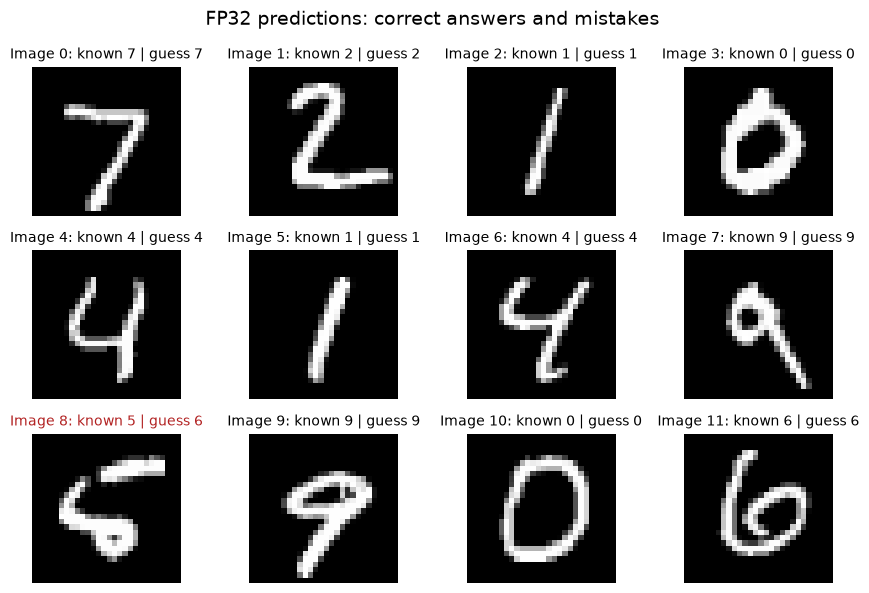

Inspected image 0: known 7, FP32 guess 7


In [53]:
fig, axes = plt.subplots(3, 4, figsize=(9, 6))
for index, ax in enumerate(axes.flat):
    wrong = fp_predictions[index] != labels[index]
    ax.imshow(inputs[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Image {index}: known {labels[index]} | guess {fp_predictions[index]}",
                 color="firebrick" if wrong else "black", fontsize=10)
    ax.axis("off")
fig.suptitle("FP32 predictions: correct answers and mistakes", fontsize=14)
fig.tight_layout()
plt.show()
print(f"Inspected image {image_index}: known {labels[image_index]}, FP32 guess {fp_predictions[image_index]}")


## 10 Check the data and the FP32 baseline

The six data checks remain. Five additional checks cover a hand-calculated
network, training on a small known pattern, the reserved data split, real model
types and shapes, and complete test predictions. A broad 90% accuracy floor is
a sanity check for a functioning baseline, not a target used to tune the model.


In [54]:
class MnistDataTests(unittest.TestCase):
    def test_known_image_record(self):
        record = struct.pack(">IIII", 2051, 1, 28, 28) + bytes([255] * 784)
        decoded = decode_images(record)
        self.assertEqual(decoded.shape, (1, 784))
        self.assertEqual(decoded.dtype, np.uint8)
        self.assertTrue(np.all(decoded == 255))

    def test_reject_malformed_image_records(self):
        valid = struct.pack(">IIII", 2051, 1, 28, 28) + bytes(784)
        for record in (b"", valid[:-1], struct.pack(">IIII", 0, 1, 28, 28) + bytes(784)):
            with self.subTest(size=len(record)), self.assertRaises(ValueError):
                decode_images(record)

    def test_known_labels_and_reject_bad_records(self):
        valid = struct.pack(">II", 2049, 2) + bytes([3, 7])
        self.assertEqual(decode_labels(valid).tolist(), [3, 7])
        for record in (b"", valid[:-1], struct.pack(">II", 2049, 1) + bytes([10])):
            with self.subTest(size=len(record)), self.assertRaises(ValueError):
                decode_labels(record)

    def test_checksum_rejects_changed_content(self):
        expected = "5d41402abc4b2a76b9719d911017c592"
        self.assertEqual(check_file_identity(b"hello", expected), b"hello")
        with self.assertRaises(ValueError):
            check_file_identity(b"changed", expected)

    def test_known_normalized_values(self):
        normalized = normalize_pixels(np.array([[0, 127, 255]], dtype=np.uint8))
        self.assertEqual(normalized.dtype, np.float32)
        np.testing.assert_allclose(normalized, [[0.0, 0.4980392156862745, 1.0]], rtol=1e-6)

    def test_real_test_set_shape_and_labels(self):
        self.assertEqual(inputs.shape, (10000, 784))
        self.assertEqual(labels.shape, (10000,))
        self.assertTrue(np.all((labels >= 0) & (labels <= 9)))
        self.assertEqual(int(labels[0]), 7)
        self.assertEqual(int(labels[8]), 5)
        self.assertGreaterEqual(float(inputs.min()), 0)
        self.assertLessEqual(float(inputs.max()), 1)


class FP32BaselineTests(unittest.TestCase):
    def test_hand_calculated_forward_with_bias_and_relu(self):
        model = {
            "w1": np.array([[1, -1], [2, 1]], dtype=np.float32),
            "b1": np.array([0, -5], dtype=np.float32),
            "w2": np.array([[2, -1], [3, 4]], dtype=np.float32),
            "b2": np.array([1, 2], dtype=np.float32),
        }
        hidden, scores = forward_fp32(np.array([[1, 2]], dtype=np.float32), model)
        np.testing.assert_array_equal(hidden, [[5, 0]])
        np.testing.assert_array_equal(scores, [[11, -3]])
        self.assertEqual(hidden.dtype, np.float32)
        self.assertEqual(scores.dtype, np.float32)

    def test_training_learns_a_small_known_pattern(self):
        targets = np.tile(np.arange(10, dtype=np.uint8), 8)
        examples = np.zeros((80, 784), dtype=np.float32)
        examples[np.arange(80), targets] = 1
        learned, history = train(examples, targets, examples, targets, epochs=30,
                                 hidden_units=16, batch_size=80, learning_rate=0.03,
                                 progress=lambda message: None)
        self.assertLess(history[-1]["training_loss"], history[0]["training_loss"])
        self.assertGreaterEqual(history[-1]["validation_accuracy"], 0.9)
        self.assertTrue(all(value.dtype == np.float32 for value in learned.values()))

    def test_reserved_split_is_disjoint_complete_and_repeatable(self):
        self.assertEqual([len(indices[name]) for name in ("training", "validation", "calibration")],
                         [54000, 5000, 1000])
        np.testing.assert_array_equal(np.sort(np.concatenate(list(indices.values()))), np.arange(60000))
        repeated = split_indices(seed=530)
        for name in indices:
            np.testing.assert_array_equal(indices[name], repeated[name])

    def test_real_model_shapes_types_and_finite_scores(self):
        self.assertEqual(fp_model["w1"].shape, (784, 64))
        self.assertEqual(fp_model["w2"].shape, (64, 10))
        self.assertTrue(all(value.dtype == np.float32 for value in fp_model.values()))
        hidden, scores = forward_fp32(inputs[:16], fp_model)
        self.assertEqual(hidden.shape, (16, 64))
        self.assertEqual(scores.shape, (16, 10))
        self.assertEqual(scores.dtype, np.float32)
        self.assertTrue(np.all(np.isfinite(scores)))
        np.testing.assert_array_equal(scores.argmax(axis=1), fp_predictions[:16])

    def test_complete_test_predictions_and_baseline_sanity(self):
        self.assertEqual(fp_predictions.shape, (10000,))
        self.assertTrue(np.all((fp_predictions >= 0) & (fp_predictions <= 9)))
        self.assertEqual(fp_correct, int(np.sum(fp_predictions == labels)))
        self.assertGreaterEqual(fp_accuracy_percent, 90.0)

suite = unittest.TestSuite([
    unittest.defaultTestLoader.loadTestsFromTestCase(MnistDataTests),
    unittest.defaultTestLoader.loadTestsFromTestCase(FP32BaselineTests),
])
result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
if not result.wasSuccessful():
    raise AssertionError("A data or FP32 check failed; review the output above.")
print(f"All {result.testsRun} data and FP32 baseline checks passed.")


test_checksum_rejects_changed_content (__main__.MnistDataTests.test_checksum_rejects_changed_content) ... ok
test_known_image_record (__main__.MnistDataTests.test_known_image_record) ... ok
test_known_labels_and_reject_bad_records (__main__.MnistDataTests.test_known_labels_and_reject_bad_records) ... ok
test_known_normalized_values (__main__.MnistDataTests.test_known_normalized_values) ... ok
test_real_test_set_shape_and_labels (__main__.MnistDataTests.test_real_test_set_shape_and_labels) ... ok
test_reject_malformed_image_records (__main__.MnistDataTests.test_reject_malformed_image_records) ... ok
test_complete_test_predictions_and_baseline_sanity (__main__.FP32BaselineTests.test_complete_test_predictions_and_baseline_sanity) ... ok
test_hand_calculated_forward_with_bias_and_relu (__main__.FP32BaselineTests.test_hand_calculated_forward_with_bias_and_relu) ... ok
test_real_model_shapes_types_and_finite_scores (__main__.FP32BaselineTests.test_real_model_shapes_types_and_finite_scores) .

## Next increment

We now have actual FP32 predictions and a measured test accuracy. Next we will
quantize this same trained network and compare INT8 predictions with the FP32
baseline. The calibration reserve will be used to choose the intermediate-value
scale. Accelerator timing comes in its own later increment.

**Design context:** Brevitas' guide distinguishes a floating-point baseline from
post-training quantization of that model. This notebook implements our own NumPy
baseline; it does not run Brevitas or claim framework equivalence.
[https://xilinx.github.io/brevitas/v0.13.4/getting_started.html](https://xilinx.github.io/brevitas/v0.13.4/getting_started.html).

**MNIST file identities and mirror:**
[https://github.com/pytorch/vision/blob/main/torchvision/datasets/mnist.py](https://github.com/pytorch/vision/blob/main/torchvision/datasets/mnist.py).


## INT8 Post-Training Quantization
Next, we quantize the trained FP32 model to INT8 and evaluate its accuracy without retraining the network.

In [55]:
def quantize_weight_matrix(weights):
    weights = np.asarray(weights, dtype=np.float32)
    max_abs = np.max(np.abs(weights))
    scale = float(max_abs / 127.0) if max_abs else 1.0

    scaled = weights / scale
    clipped = np.clip(scaled, -127, 127)
    quantized = np.rint(clipped).astype(np.int8)
    return quantized, scale


w1_int8, w1_scale = quantize_weight_matrix(fp_model["w1"])
w2_int8, w2_scale = quantize_weight_matrix(fp_model["w2"])

for name, original, quantized, scale in (
    ("First-layer weights", fp_model["w1"], w1_int8, w1_scale),
    ("Second-layer weights", fp_model["w2"], w2_int8, w2_scale),
):
    print(f"{name}:")
    print(f"  FP32 shape: {original.shape}")
    print(f"  INT8 shape: {quantized.shape}")
    print(f"  FP32 min/max: {original.min():.6f} / {original.max():.6f}")
    print(f"  INT8 min/max: {quantized.min()} / {quantized.max()}")
    print(f"  Quantization scale: {scale:.10g}")

First-layer weights:
  FP32 shape: (784, 64)
  INT8 shape: (784, 64)
  FP32 min/max: -0.710802 / 0.458153
  INT8 min/max: -127 / 82
  Quantization scale: 0.005596864037
Second-layer weights:
  FP32 shape: (64, 10)
  INT8 shape: (64, 10)
  FP32 min/max: -1.009917 / 0.917818
  INT8 min/max: -127 / 115
  Quantization scale: 0.007952104323


## INT8 Input Quantization

Quantize the MNIST test inputs to signed INT8 using the same symmetric quantization method before implementing full INT8 inference.

In [56]:
test_input_fp32 = inputs
max_abs = np.max(np.abs(test_input_fp32))
input_scale = float(max_abs / 127.0) if max_abs else 1.0

inputs_int8 = np.rint(
    np.clip(test_input_fp32 / input_scale, -127, 127)
).astype(np.int8)

print("FP32 input shape:", test_input_fp32.shape)
print("INT8 input shape:", inputs_int8.shape)
print(f"FP32 min/max: {test_input_fp32.min():.6f} / {test_input_fp32.max():.6f}")
print("INT8 min/max:", inputs_int8.min(), "/", inputs_int8.max())
print(f"Input quantization scale: {input_scale:.10g}")

FP32 input shape: (10000, 784)
INT8 input shape: (10000, 784)
FP32 min/max: 0.000000 / 1.000000
INT8 min/max: 0 / 127
Input quantization scale: 0.007874015719


## INT8 First Layer

Perform the first linear layer using INT8 inputs and INT8 weights, accumulate in INT32, then convert the result back to FP32 for comparison.

In [57]:
int32_linear_output = (
    inputs_int8.astype(np.int32) @ w1_int8.astype(np.int32)
)

output_scale = input_scale * w1_scale
dequantized_linear_output = (
    int32_linear_output.astype(np.float32) * output_scale
    + fp_model["b1"]
)

fp32_linear_output = inputs @ fp_model["w1"] + fp_model["b1"]

absolute_error = np.abs(dequantized_linear_output - fp32_linear_output)

print("INT32 output shape:", int32_linear_output.shape)
print("Dequantized output shape:", dequantized_linear_output.shape)
print("FP32 output shape:", fp32_linear_output.shape)
print(f"Mean absolute error: {absolute_error.mean():.8f}")
print(f"Maximum absolute error: {absolute_error.max():.8f}")

INT32 output shape: (10000, 64)
Dequantized output shape: (10000, 64)
FP32 output shape: (10000, 64)
Mean absolute error: 0.01300873
Maximum absolute error: 0.08711338


## Quantized Hidden Activation

Apply ReLU to the first-layer output, then quantize the hidden activation to INT8 for use by the second layer.

In [58]:
int8_relu_output = np.maximum(dequantized_linear_output, np.float32(0))
fp32_relu_output = np.maximum(fp32_linear_output, np.float32(0))

max_abs_activation = np.max(np.abs(int8_relu_output))
activation_scale = (
    float(max_abs_activation / 127.0) if max_abs_activation else 1.0
)
int8_activation = np.rint(
    np.clip(int8_relu_output / activation_scale, -127, 127)
).astype(np.int8)

dequantized_int8_activation = int8_activation.astype(np.float32) * activation_scale
activation_error = np.abs(fp32_relu_output - dequantized_int8_activation)

print("FP32 ReLU output shape:", fp32_relu_output.shape)
print("INT8 activation shape:", int8_activation.shape)
print(f"FP32 ReLU min/max: {fp32_relu_output.min():.6f} / {fp32_relu_output.max():.6f}")
print("INT8 activation min/max:", int8_activation.min(), "/", int8_activation.max())
print(f"Activation quantization scale: {activation_scale:.10g}")
print(f"Mean absolute error: {activation_error.mean():.8f}")

FP32 ReLU output shape: (10000, 64)
INT8 activation shape: (10000, 64)
FP32 ReLU min/max: 0.000000 / 16.087202
INT8 activation min/max: 0 / 127
Activation quantization scale: 0.1264669746
Mean absolute error: 0.02051183


## INT8 Output Layer and Accuracy

Use the quantized hidden activations and quantized second-layer weights to compute the final logits and evaluate INT8 classification accuracy.

In [59]:
int32_second_layer_output = (
    int8_activation.astype(np.int32) @ w2_int8.astype(np.int32)
)

second_output_scale = activation_scale * w2_scale
int8_logits = (
    int32_second_layer_output.astype(np.float32) * second_output_scale
    + fp_model["b2"]
)

fp32_logits = (
    fp32_relu_output @ fp_model["w2"] + fp_model["b2"]
)

int8_final_predictions = int8_logits.argmax(axis=1)
fp32_final_predictions = fp32_logits.argmax(axis=1)

fp32_test_accuracy = np.mean(fp32_final_predictions == labels) * 100
int8_test_accuracy = np.mean(int8_final_predictions == labels) * 100
accuracy_difference_pp = int8_test_accuracy - fp32_test_accuracy
prediction_disagreements = np.count_nonzero(
    fp32_final_predictions != int8_final_predictions
)

print("INT32 second-layer output shape:", int32_second_layer_output.shape)
print("INT8/dequantized logits shape:", int8_logits.shape)
print("FP32 logits shape:", fp32_logits.shape)
print(f"FP32 test accuracy: {fp32_test_accuracy:.2f}%")
print(f"INT8 test accuracy: {int8_test_accuracy:.2f}%")
print(f"Accuracy difference (INT8 - FP32): {accuracy_difference_pp:+.2f} percentage points")
print("FP32/INT8 prediction disagreements:", prediction_disagreements)

INT32 second-layer output shape: (10000, 10)
INT8/dequantized logits shape: (10000, 10)
FP32 logits shape: (10000, 10)
FP32 test accuracy: 96.96%
INT8 test accuracy: 96.99%
Accuracy difference (INT8 - FP32): +0.03 percentage points
FP32/INT8 prediction disagreements: 7
